# 7 · How functional is the irrigation? Comparing Γ = 0, 0.5 and 1

The course notes ([`original/course-notes/07-vessel-model-and-gamma.jpg`](../../original/course-notes/07-vessel-model-and-gamma.jpg)) describe $\Gamma$ as "how functional the irrigation is" and try $\Gamma = 0$, $0.5$ and $1$. This notebook runs all three in the irrigation model of [notebook 5](05-diffusion-proliferation-irrigation.ipynb):

$$\frac{\partial n}{\partial t} = D\,\nabla^2 n + \big[\alpha_0 + \alpha_1\,(V - 1)^{\Gamma}\big]\, n\left(1 - \frac{n}{N_{\max}}\right), \qquad \frac{\partial V}{\partial t} = \beta(x)\, n\, V \left(1 - \frac{V}{V_{\max}}\right)$$

The boost $(V-1)^{\Gamma}$ is taken as 0 where no new vessels have formed ($V = 1$). That matters only for $\Gamma = 0$, where $0^0$ would otherwise count as 1 and boost growth even without any vessels.

**Experiment.** Same set-up as notebook 5: $\beta = 0.001$ on the left half and $0.1$ on the right. A control run has no vessel growth at all ($\beta = 0$). The tumour area is the number of grid cells with density above 0.5, counted separately in each half.

In [1]:
import sys
sys.path.insert(0, "..")    # shared code lives in corrected/angiogenesis.py
import numpy as np
import matplotlib.pyplot as plt
import angiogenesis as ag

In [2]:
l = 200
delta_t = 0.1
delta_x = 1
D = 0.2
Alpha_zero = 1
Alpha_one = 1
V_max = 4
N_Max = 1
cutoff = 1e-3
gammas = [0, 0.5, 1]
num_steps = 500
snapshot_step = 300

ag.check_stability(D, delta_t, delta_x)
n_initial = ag.three_regions(l, cutoff=cutoff)
beta = ag.beta_split(l, 0.001, 0.1)

In [3]:
def simulate(gamma, beta):
    """Return the fields at `snapshot_step` and the tumour area over time."""
    n = n_initial.copy()
    V = np.ones((l, l))
    area = {"t": [], "left": [], "right": []}
    for step in range(1, num_steps + 1):
        n, V = ag.irrigation_step(n, V, beta, D, Alpha_zero, Alpha_one, gamma,
                                  N_Max, V_max, delta_t, delta_x)
        if step % 10 == 0:
            area["t"].append(step * delta_t)
            area["left"].append(int((n[:, : l // 2] > 0.5).sum()))
            area["right"].append(int((n[:, l // 2 :] > 0.5).sum()))
        if step == snapshot_step:
            snapshot = (n.copy(), V.copy())
    return snapshot, area

runs = {"control: no vessel growth": simulate(0.5, np.zeros((l, l)))}
for g in gammas:
    runs[f"Γ = {g}"] = simulate(g, beta)

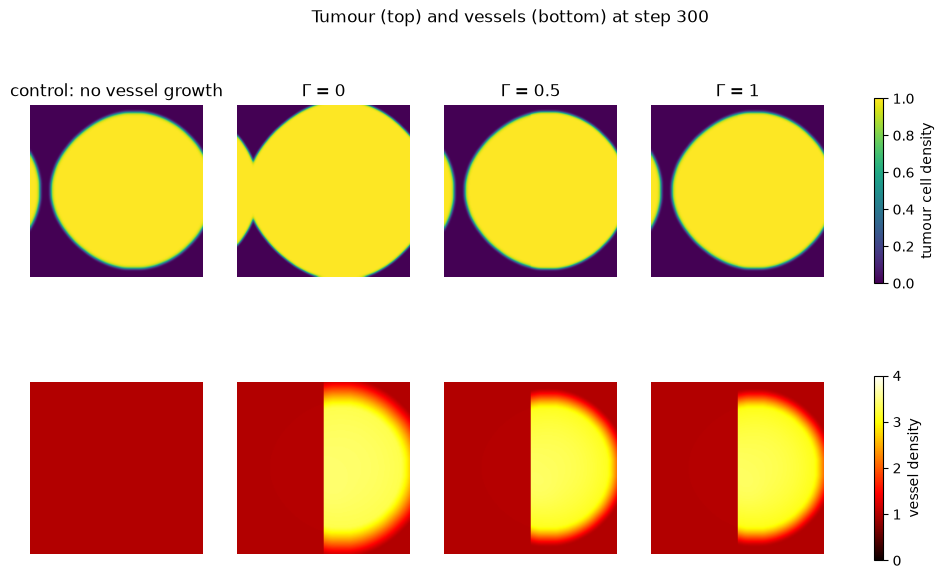

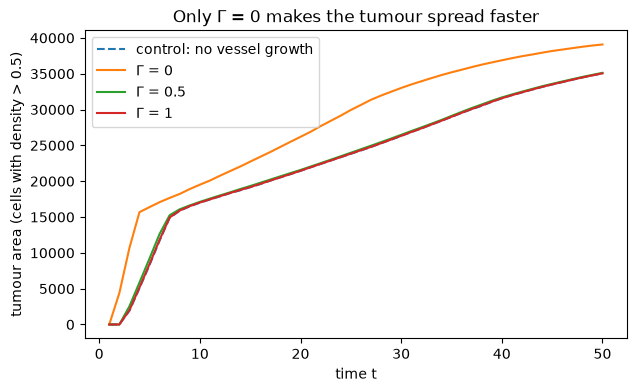

In [4]:
fig, axes = plt.subplots(2, len(runs), figsize=(3.2 * len(runs), 6.6))
for col, (name, ((n, V), _)) in enumerate(runs.items()):
    im_n = axes[0, col].imshow(n, origin="lower", cmap="viridis", vmin=0, vmax=N_Max)
    im_v = axes[1, col].imshow(V, origin="lower", cmap="hot", vmin=0, vmax=V_max)
    axes[0, col].set_title(name)
for ax in axes.flat:
    ax.axis("off")
fig.colorbar(im_n, ax=axes[0], shrink=0.8, label="tumour cell density")
fig.colorbar(im_v, ax=axes[1], shrink=0.8, label="vessel density")
fig.suptitle(f"Tumour (top) and vessels (bottom) at step {snapshot_step}")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for name, (_, area) in runs.items():
    total = np.array(area["left"]) + np.array(area["right"])
    ax.plot(area["t"], total, "--" if name.startswith("control") else "-", label=name)
ax.set_xlabel("time t")
ax.set_ylabel("tumour area (cells with density > 0.5)")
ax.legend()
ax.set_title("Only Γ = 0 makes the tumour spread faster")
plt.show()

In [5]:
control = runs["control: no vessel growth"][1]
for step in (100, 200, 300):
    k = step // 10 - 1
    print(f"step {step}")
    for name, (_, area) in runs.items():
        left, right = area["left"][k], area["right"][k]
        change = ("" if name.startswith("control") else
                  f"   ({100 * (left / control['left'][k] - 1):+.1f} % / {100 * (right / control['right'][k] - 1):+.1f} % vs control)")
        print(f"  {name:28s} left {left:6d}  right {right:6d}{change}")

step 100
  control: no vessel growth    left   5782  right  11218
  Γ = 0                        left   6836  right  12675   (+18.2 % / +13.0 % vs control)
  Γ = 0.5                      left   5800  right  11314   (+0.3 % / +0.9 % vs control)
  Γ = 1                        left   5783  right  11236   (+0.0 % / +0.2 % vs control)
step 200
  control: no vessel growth    left   7716  right  13733
  Γ = 0                        left  10334  right  15857   (+33.9 % / +15.5 % vs control)
  Γ = 0.5                      left   7729  right  13837   (+0.2 % / +0.8 % vs control)
  Γ = 1                        left   7716  right  13741   (+0.0 % / +0.1 % vs control)
step 300
  control: no vessel growth    left  10410  right  15915
  Γ = 0                        left  14529  right  18482   (+39.6 % / +16.1 % vs control)
  Γ = 0.5                      left  10433  right  16035   (+0.2 % / +0.8 % vs control)
  Γ = 1                        left  10411  right  15922   (+0.0 % / +0.0 % vs control)


**Reading the result.**

- **Γ = 0.5 and Γ = 1: the vessels barely matter.** The tumour area changes by less than 1 % compared with the control, as notebook 5 found for $\Gamma = 0.5$.
- **Γ = 0: the vessels clearly matter.** By step 300 the tumour covers about 40 % more area on the left and 16 % more on the right.
- **Why.** The tumour front is driven by the sparse cells at its leading edge. Vessels start growing there as soon as any tumour cells arrive, but $V$ is still only a hair above 1.
  - With $\Gamma = 0$, $(V-1)^0 = 1$ as soon as $V > 1$, so the leading edge immediately gets the full boost $\alpha_0 + \alpha_1 = 2$. The front speed $2\sqrt{D\alpha}$ then rises by about $\sqrt{2}$.
  - With $\Gamma = 0.5$ or $1$, $(V - 1)^{\Gamma}$ is still almost zero at the edge. The boost only builds up behind the front, where the tumour is already at $N_{\max}$ and has no room left to grow.
- **Even the left half speeds up under Γ = 0**, although its $\beta$ is 100× smaller. With $\Gamma = 0$ it does not matter *how many* vessels form, only *whether* any do.

So in this model, "how functional the irrigation is" decides whether vessels affect the tumour at all. They help only if even a little new vasculature is fully effective right where the tumour is advancing.